# Cybersecurity Analytics & Intrusion Detection Dashboard
## Notebook 1 — Chargement, fusion et nettoyage (CICIDS2017)

**Objectifs**
1. Charger les 8 fichiers CSV de CICIDS2017 et les fusionner
2. Conserver **l'origine de chaque ligne** (`Source_File`, `Day`, `Row_Order`) — indispensable pour le split temporel du Notebook 2
3. Nettoyer (NaN, infinis, doublons, colonne dupliquée)
4. Créer `Attack_Category`, `Is_Attack` et quelques features
5. Exporter le dataset nettoyé (ML) + les tables agrégées (Power BI)

> Ordre d'exécution du projet : **01 → 02 → 02b → 03**, puis Power BI.

## 1. Imports et configuration

In [1]:
import glob
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100)

RAW_DIR = "../data/raw/"
PROCESSED_DIR = "../data/processed/"
RESULTS_DIR = "../results/"
IMAGES_DIR = "../images/"

for d in (PROCESSED_DIR, RESULTS_DIR, IMAGES_DIR):
    os.makedirs(d, exist_ok=True)

print("Configuration OK.")

Configuration OK.


## 2. Fichiers disponibles

On doit trouver les **8 fichiers CSV** de CICIDS2017 dans `data/raw/`.

In [2]:
all_files = sorted(glob.glob(os.path.join(RAW_DIR, "*.csv")))
print(f"Nombre de fichiers trouvés : {len(all_files)}\n")
for f in all_files:
    print(" -", os.path.basename(f))

assert len(all_files) == 8, "Il manque des fichiers dans data/raw/ (8 attendus)."

Nombre de fichiers trouvés : 8

 - Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
 - Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
 - Friday-WorkingHours-Morning.pcap_ISCX.csv
 - Monday-WorkingHours.pcap_ISCX.csv
 - Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
 - Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
 - Tuesday-WorkingHours.pcap_ISCX.csv
 - Wednesday-workingHours.pcap_ISCX.csv


## 3. Chargement et fusion

Pour chaque fichier on :
- nettoie les noms de colonnes (espaces parasites, problème connu de CICIDS2017),
- ajoute `Source_File` (fichier d'origine) et `Row_Order` (position de la ligne dans son fichier).

`Row_Order` sert à reconstituer l'ordre **approximativement chronologique** des flux (les flux sont écrits par CICFlowMeter dans l'ordre de la capture). Ce n'est **pas** une feature : elle sera exclue du ML.

In [3]:
dfs = []
for f in all_files:
    tmp = pd.read_csv(f, encoding="latin1", low_memory=False)
    tmp.columns = tmp.columns.str.strip()
    tmp["Source_File"] = os.path.splitext(os.path.basename(f))[0]
    tmp["Row_Order"] = np.arange(len(tmp))
    dfs.append(tmp)
    print(f"{os.path.basename(f):<60} -> {tmp.shape}")

df = pd.concat(dfs, ignore_index=True)
del dfs

# "Wednesday-workingHours.pcap_ISCX" -> "Wednesday"
df["Day"] = df["Source_File"].str.split("-").str[0].str.capitalize()
df["Label"] = df["Label"].str.strip()

print("\nShape après fusion :", df.shape)
print(df["Day"].value_counts())

Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv             -> (225745, 81)
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv         -> (286467, 81)
Friday-WorkingHours-Morning.pcap_ISCX.csv                    -> (191033, 81)
Monday-WorkingHours.pcap_ISCX.csv                            -> (529918, 81)
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv  -> (288602, 81)
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv       -> (170366, 81)
Tuesday-WorkingHours.pcap_ISCX.csv                           -> (445909, 81)
Wednesday-workingHours.pcap_ISCX.csv                         -> (692703, 81)

Shape après fusion : (2830743, 82)
Day
Friday       703245
Wednesday    692703
Monday       529918
Thursday     458968
Tuesday      445909
Name: count, dtype: int64


## 4. Aperçu et distribution brute des labels

In [4]:
df.head()

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Min Packet Length,Max Packet Length,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWE Flag Count,ECE Flag Count,Down/Up Ratio,Average Packet Size,Avg Fwd Segment Size,Avg Bwd Segment Size,Fwd Header Length.1,Fwd Avg Bytes/Bulk,Fwd Avg Packets/Bulk,Fwd Avg Bulk Rate,Bwd Avg Bytes/Bulk,Bwd Avg Packets/Bulk,Bwd Avg Bulk Rate,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,Init_Win_bytes_forward,Init_Win_bytes_backward,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,Source_File,Row_Order,Day
0,54865,3,2,0,12,0,6,6,6.0,0.0,0,0,0.0,0.0,4.000000e+06,666666.66670,3.0,0.0,3,3,3,3.0,0.0,3,3,0,0.0,0.0,0,0,0,0,0,0,40,0,666666.666700,0.000000,6,6,6.0,0.0,0.0,0,0,0,0,1,0,0,0,0,9.0,6.0,0.0,40,0,0,0,0,0,0,2,12,0,0,33,-1,1,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX,0,Friday
1,55054,109,1,1,6,6,6,6,6.0,0.0,6,6,6.0,0.0,1.100917e+05,18348.62385,109.0,0.0,109,109,0,0.0,0.0,0,0,0,0.0,0.0,0,0,0,0,0,0,20,20,9174.311927,9174.311927,6,6,6.0,0.0,0.0,0,0,0,0,1,1,0,0,1,9.0,6.0,6.0,20,0,0,0,0,0,0,1,6,1,6,29,256,0,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX,1,Friday
2,55055,52,1,1,6,6,6,6,6.0,0.0,6,6,6.0,0.0,2.307692e+05,38461.53846,52.0,0.0,52,52,0,0.0,0.0,0,0,0,0.0,0.0,0,0,0,0,0,0,20,20,19230.769230,19230.769230,6,6,6.0,0.0,0.0,0,0,0,0,1,1,0,0,1,9.0,6.0,6.0,20,0,0,0,0,0,0,1,6,1,6,29,256,0,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX,2,Friday
3,46236,34,1,1,6,6,6,6,6.0,0.0,6,6,6.0,0.0,3.529412e+05,58823.52941,34.0,0.0,34,34,0,0.0,0.0,0,0,0,0.0,0.0,0,0,0,0,0,0,20,20,29411.764710,29411.764710,6,6,6.0,0.0,0.0,0,0,0,0,1,1,0,0,1,9.0,6.0,6.0,20,0,0,0,0,0,0,1,6,1,6,31,329,0,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX,3,Friday
4,54863,3,2,0,12,0,6,6,6.0,0.0,0,0,0.0,0.0,4.000000e+06,666666.66670,3.0,0.0,3,3,3,3.0,0.0,3,3,0,0.0,0.0,0,0,0,0,0,0,40,0,666666.666700,0.000000,6,6,6.0,0.0,0.0,0,0,0,0,1,0,0,0,0,9.0,6.0,0.0,40,0,0,0,0,0,0,2,12,0,0,32,-1,1,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX,4,Friday


In [5]:
print(df["Label"].value_counts())

Label
BENIGN                          2273097
DoS Hulk                         231073
PortScan                         158930
DDoS                             128027
DoS GoldenEye                     10293
FTP-Patator                        7938
SSH-Patator                        5897
DoS slowloris                      5796
DoS Slowhttptest                   5499
Bot                                1966
Web Attack ï¿½ Brute Force         1507
Web Attack ï¿½ XSS                  652
Infiltration                         36
Web Attack ï¿½ Sql Injection         21
Heartbleed                           11
Name: count, dtype: int64


## 5. Préparation des colonnes

- Conversion en numérique des colonnes de features (certaines contiennent `Infinity` sous forme de texte).
- La colonne `Fwd Header Length.1` est un doublon exact de `Fwd Header Length` (connu dans CICIDS2017) : on la supprime après vérification.

In [6]:
META_COLS = ["Label", "Source_File", "Row_Order", "Day"]
feature_cols = [c for c in df.columns if c not in META_COLS]

df[feature_cols] = df[feature_cols].apply(pd.to_numeric, errors="coerce")

if "Fwd Header Length.1" in df.columns:
    if df["Fwd Header Length"].equals(df["Fwd Header Length.1"]):
        df = df.drop(columns=["Fwd Header Length.1"])
        print("Colonne dupliquée 'Fwd Header Length.1' supprimée (identique à 'Fwd Header Length').")
    else:
        print("Attention : 'Fwd Header Length.1' diffère de 'Fwd Header Length', conservée.")

feature_cols = [c for c in df.columns if c not in META_COLS]
print("Nombre de features réseau :", len(feature_cols))

Colonne dupliquée 'Fwd Header Length.1' supprimée (identique à 'Fwd Header Length').
Nombre de features réseau : 77


## 6. Diagnostic avant nettoyage

Combien de lignes allons-nous perdre ? (infinis → NaN, NaN, doublons)

> Les doublons sont détectés sur les **features + Label** uniquement (pas sur `Source_File`/`Row_Order`, qui sont toujours uniques).

In [7]:
n_before = len(df)
n_inf = int(np.isinf(df[feature_cols]).sum().sum())
n_nan = int(df[feature_cols].isna().sum().sum())
n_dup = int(df.duplicated(subset=feature_cols + ["Label"]).sum())

print("Lignes avant nettoyage :", n_before)
print("Valeurs infinies       :", n_inf)
print("Valeurs NaN            :", n_nan)
print("Lignes dupliquées      :", n_dup)

Lignes avant nettoyage : 2830743
Valeurs infinies       : 4376
Valeurs NaN            : 1358
Lignes dupliquées      : 308381


## 7. Nettoyage

In [8]:
df = df.replace([np.inf, -np.inf], np.nan)
df = df.dropna(subset=feature_cols)
n_after_na = len(df)

df = df.drop_duplicates(subset=feature_cols + ["Label"])
n_after = len(df)

print("Après suppression NaN/inf :", n_after_na)
print("Après suppression doublons :", n_after)
print(f"Lignes conservées : {n_after / n_before * 100:.2f}%")

df = df.reset_index(drop=True)

Après suppression NaN/inf : 2827876
Après suppression doublons : 2520798
Lignes conservées : 89.05%


In [9]:
print(df["Label"].value_counts())

Label
BENIGN                          2095057
DoS Hulk                         172846
DDoS                             128014
PortScan                          90694
DoS GoldenEye                     10286
FTP-Patator                        5931
DoS slowloris                      5385
DoS Slowhttptest                   5228
SSH-Patator                        3219
Bot                                1948
Web Attack ï¿½ Brute Force         1470
Web Attack ï¿½ XSS                  652
Infiltration                         36
Web Attack ï¿½ Sql Injection         21
Heartbleed                           11
Name: count, dtype: int64


## 8. Catégories d'attaque

On regroupe les sous-types en catégories principales (pour le ML et pour Power BI).

In [10]:
def categorize_attack(label):
    if label == "BENIGN":
        return "Benign"
    elif "DDoS" in label:
        return "DDoS"
    elif "DoS" in label:
        return "DoS"
    elif "Patator" in label:
        return "Brute Force"
    elif "PortScan" in label:
        return "Port Scan"
    elif "Web Attack" in label:
        return "Web Attack"
    elif "Bot" in label:
        return "Bot"
    elif "Infiltration" in label:
        return "Infiltration"
    elif "Heartbleed" in label:
        return "Heartbleed"
    return "Other"

df["Attack_Category"] = df["Label"].apply(categorize_attack)

assert (df["Attack_Category"] != "Other").all(), "Label inconnu : vérifier categorize_attack()"

print(df["Attack_Category"].value_counts())
print()
print((df["Attack_Category"].value_counts(normalize=True) * 100).round(3))

Attack_Category
Benign          2095057
DoS              193745
DDoS             128014
Port Scan         90694
Brute Force        9150
Web Attack         2143
Bot                1948
Infiltration         36
Heartbleed           11
Name: count, dtype: int64

Attack_Category
Benign          83.111
DoS              7.686
DDoS             5.078
Port Scan        3.598
Brute Force      0.363
Web Attack       0.085
Bot              0.077
Infiltration     0.001
Heartbleed       0.000
Name: proportion, dtype: float64


## 9. Features supplémentaires

- `Is_Attack` : 0 = Benign, 1 = attaque (**cible dérivée — jamais utilisée comme feature**)
- `Traffic_Volume` : nombre total de paquets
- `Total_Bytes` : nombre total d'octets

In [11]:
df["Is_Attack"] = (df["Attack_Category"] != "Benign").astype(int)
df["Traffic_Volume"] = df["Total Fwd Packets"] + df["Total Backward Packets"]
df["Total_Bytes"] = df["Total Length of Fwd Packets"] + df["Total Length of Bwd Packets"]

df[["Label", "Attack_Category", "Is_Attack", "Traffic_Volume", "Total_Bytes"]].head()

,Label,Attack_Category,Is_Attack,Traffic_Volume,Total_Bytes
0,BENIGN,Benign,0,2,12
1,BENIGN,Benign,0,2,12
2,BENIGN,Benign,0,2,12
3,BENIGN,Benign,0,2,12
4,BENIGN,Benign,0,2,12


## 10. Déséquilibre des classes

CICIDS2017 est **très déséquilibré**. L'Accuracy seule est donc trompeuse : au Notebook 2 on utilisera surtout le **Macro F1** et le **Recall par classe**.

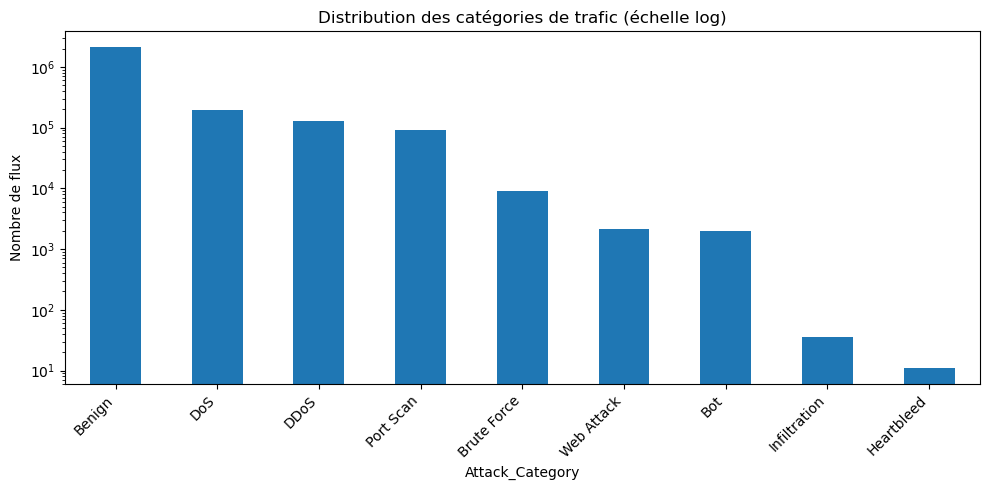

In [12]:
counts = df["Attack_Category"].value_counts()

plt.figure(figsize=(10, 5))
counts.plot(kind="bar", color="#1f77b4")
plt.title("Distribution des catégories de trafic (échelle log)")
plt.ylabel("Nombre de flux")
plt.yscale("log")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(IMAGES_DIR + "class_distribution.png", dpi=150)
plt.show()

## 11. Exports

**Pour le Machine Learning**
- `data/processed/cleaned_network_traffic.csv`

**Pour Power BI** (`results/`)
- `attack_summary.csv` — volume par catégorie
- `label_summary.csv` — volume par label détaillé
- `daily_summary.csv` — volume par jour × catégorie
- `port_summary.csv` — top 15 des ports de destination × catégorie
- `traffic_stats.csv` — statistiques moyennes par catégorie
- `data_quality.csv` — bilan du nettoyage

In [13]:
# --- Dataset nettoyé (ML) ---
df.to_csv(PROCESSED_DIR + "cleaned_network_traffic.csv", index=False)
print("cleaned_network_traffic.csv exporté :", df.shape)

# --- Résumé par catégorie ---
attack_summary = df["Attack_Category"].value_counts().reset_index()
attack_summary.columns = ["Attack_Category", "Count"]
attack_summary["Percentage"] = (attack_summary["Count"] / attack_summary["Count"].sum() * 100).round(3)
attack_summary.to_csv(RESULTS_DIR + "attack_summary.csv", index=False)

# --- Résumé par label détaillé ---
label_summary = df.groupby(["Attack_Category", "Label"]).size().reset_index(name="Count")
label_summary.to_csv(RESULTS_DIR + "label_summary.csv", index=False)

# --- Résumé par jour x catégorie ---
day_order = {"Monday": 1, "Tuesday": 2, "Wednesday": 3, "Thursday": 4, "Friday": 5}
daily_summary = df.groupby(["Day", "Attack_Category"]).size().reset_index(name="Count")
daily_summary["Day_Order"] = daily_summary["Day"].map(day_order)
daily_summary = daily_summary.sort_values(["Day_Order", "Attack_Category"])
daily_summary.to_csv(RESULTS_DIR + "daily_summary.csv", index=False)

# --- Top 15 ports de destination x catégorie ---
top_ports = df["Destination Port"].value_counts().head(15).index
port_summary = (
    df[df["Destination Port"].isin(top_ports)]
    .groupby(["Destination Port", "Attack_Category"]).size()
    .reset_index(name="Count")
)
port_summary["Destination Port"] = port_summary["Destination Port"].astype(int)
port_summary.to_csv(RESULTS_DIR + "port_summary.csv", index=False)

# --- Statistiques moyennes par catégorie ---
traffic_stats = (
    df.groupby("Attack_Category")[["Flow Duration", "Traffic_Volume", "Total_Bytes"]]
    .mean().round(2).reset_index()
)
traffic_stats.to_csv(RESULTS_DIR + "traffic_stats.csv", index=False)

# --- Bilan du nettoyage ---
data_quality = pd.DataFrame({
    "Metric": ["Lignes brutes", "Valeurs infinies", "Valeurs NaN", "Doublons détectés",
               "Lignes après NaN/inf", "Lignes finales", "% conservé"],
    "Value": [n_before, n_inf, n_nan, n_dup, n_after_na, n_after, round(n_after / n_before * 100, 2)],
})
data_quality.to_csv(RESULTS_DIR + "data_quality.csv", index=False)

print("Tables Power BI exportées dans", RESULTS_DIR)
attack_summary

cleaned_network_traffic.csv exporté : (2520798, 85)
Tables Power BI exportées dans ../results/


,Attack_Category,Count,Percentage
0,Benign,2095057,83.111
1,DoS,193745,7.686
2,DDoS,128014,5.078
3,Port Scan,90694,3.598
4,Brute Force,9150,0.363
5,Web Attack,2143,0.085
6,Bot,1948,0.077
7,Infiltration,36,0.001
8,Heartbleed,11,0.000


## Résumé

| Étape | Résultat |
|---|---|
| Fichiers chargés | 8 CSV (CICIDS2017) |
| Traçabilité | `Source_File`, `Day`, `Row_Order` conservés |
| Nettoyage | infinis, NaN, doublons (sur features + Label), colonne dupliquée |
| Nouvelles colonnes | `Attack_Category`, `Is_Attack`, `Traffic_Volume`, `Total_Bytes` |
| Exports | 1 CSV pour le ML + 6 tables pour Power BI |

**Suite → Notebook 02 (Machine Learning).**